# Deep Learning for Perception, Assignment 2
Name: 23F-0576 | BSCS | Section 7A 

## Part B, Question 1: CIFAR-10 Classification Under Limited Data

## Step 1. Loading the data and creating the train, validation and test splits ##

In [13]:
import random
import numpy as np
import torch
import torchvision
import torchvision.transforms as T
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

DATA_SEED = 42
TEST_SEED = 2026

classes = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

In [14]:
train_full = torchvision.datasets.CIFAR10(root='.', train=True, download=True)
test_full = torchvision.datasets.CIFAR10(root='.', train=False, download=True)

print('Full train set:', train_full.data.shape)
print('Full test set: ', test_full.data.shape)

Full train set: (50000, 32, 32, 3)
Full test set:  (10000, 32, 32, 3)


In [15]:
def make_split(seed):
    rng = np.random.RandomState(seed)
    targets = np.array(train_full.targets)
    train_idx = []
    val_idx = []
    for c in range(10):
        class_idx = np.where(targets == c)[0]
        chosen = rng.choice(class_idx, 50, replace=False)
        train_idx.extend(chosen[:40])
        val_idx.extend(chosen[40:])
    return np.array(train_idx), np.array(val_idx)


def to_tensor(images):
    return torch.tensor(images).permute(0, 3, 1, 2).float() / 255.0


train_idx, val_idx = make_split(DATA_SEED)
all_targets = np.array(train_full.targets)

x_train = to_tensor(train_full.data[train_idx])
y_train = torch.tensor(all_targets[train_idx])
x_val = to_tensor(train_full.data[val_idx])
y_val = torch.tensor(all_targets[val_idx])

np.savez('split_indices.npz', train_idx=train_idx, val_idx=val_idx)
print('First 10 train indices:', train_idx[:10])
print('First 10 val indices:  ', val_idx[:10])

First 10 train indices: [14958 25814 26522 10513  7183  1097  5828 24753 24356 16075]
First 10 val indices:   [36289 41277   349   650  8383 39179 37999 46486 32058 26599]


### Test sets

- **`clean_test`**: Original 10,000 CIFAR-10 test images.
- **`shifted_test`**: Images with rotation, brightness and contrast changes, blur, noise, channel swapping, and a 16×16 grey square (25% occlusion). Random values use seed 2026.
- **`hidden_only_test`**: Original images with only the hidden corruption applied.

### Hidden corruption

I chose random RGB channel swapping because the assignment gives it as an example but does not specify the exact corruption. Each image gets one of five non-original channel orders, selected randomly.

This changes colours without changing image shape. I chose it over grayscale because training augmentation already includes saturation changes. Channel swapping is not used during training.

Both test sets are created before training and kept the same across all seeds. They are not used for training, validation, or tuning.

In [16]:
CHANNEL_PERMS = [[0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]]


def uniform(low, high, g):
    return low + (high - low) * torch.rand(1, generator=g).item()


def occlude(img, g):
    top = torch.randint(0, 17, (1,), generator=g).item()
    left = torch.randint(0, 17, (1,), generator=g).item()
    img = img.clone()
    img[:, top:top + 16, left:left + 16] = 0.5
    return img


def shift_image(img, g):
    img = TF.rotate(img, uniform(-25, 25, g), interpolation=T.InterpolationMode.BILINEAR)
    img = TF.adjust_brightness(img, uniform(0.6, 1.4, g))
    img = TF.adjust_contrast(img, uniform(0.6, 1.4, g))
    img = TF.gaussian_blur(img, kernel_size=3, sigma=uniform(0.1, 1.0, g))
    img = img + 0.03 * torch.randn(img.shape, generator=g)
    img = img.clamp(0, 1)
    perm_id = torch.randint(0, 5, (1,), generator=g).item()
    img = img[CHANNEL_PERMS[perm_id]]
    img = occlude(img, g)
    return img


def make_shifted_test(x, seed):
    g = torch.Generator().manual_seed(seed)
    return torch.stack([shift_image(img, g) for img in x])


def make_hidden_only_test(x, seed):
    g = torch.Generator().manual_seed(seed)
    perm_ids = torch.randint(0, 5, (len(x),), generator=g)
    x_out = torch.stack([img[CHANNEL_PERMS[p]] for img, p in zip(x, perm_ids.tolist())])
    return x_out, perm_ids

In [17]:
x_test = to_tensor(test_full.data)
y_test = torch.tensor(test_full.targets)

x_shifted = make_shifted_test(x_test, TEST_SEED)
x_hidden, hidden_perm_ids = make_hidden_only_test(x_test, TEST_SEED)

print('clean_test:      ', x_test.shape)
print('shifted_test:    ', x_shifted.shape)
print('hidden_only_test:', x_hidden.shape)

print('Checksums  clean: %.4f  shifted: %.4f  hidden: %.4f'
      % (x_test.sum().item(), x_shifted.sum().item(), x_hidden.sum().item()))

clean_test:       torch.Size([10000, 3, 32, 32])
shifted_test:     torch.Size([10000, 3, 32, 32])
hidden_only_test: torch.Size([10000, 3, 32, 32])
Checksums  clean: 14640690.0000  shifted: 13606429.0000  hidden: 14640688.0000


In [18]:
print('train:', tuple(x_train.shape), ' val:', tuple(x_val.shape))
print('train images per class:', torch.bincount(y_train, minlength=10).tolist())
print('val images per class:  ', torch.bincount(y_val, minlength=10).tolist())
print('test images per class: ', torch.bincount(y_test, minlength=10).tolist())

print('train/val overlap:', len(set(train_idx) & set(val_idx)))
print('unique images in train_small:', len(set(train_idx) | set(val_idx)))

same_pixels = torch.equal(x_hidden.sort(dim=1).values, x_test.sort(dim=1).values)
print('hidden-only images are channel permutations of their clean images:', same_pixels)
print('permutation counts', CHANNEL_PERMS, ':', torch.bincount(hidden_perm_ids, minlength=5).tolist())
changed = (x_hidden != x_test).flatten(1).any(dim=1).float().mean().item()
print('fraction of hidden-only images that changed: %.4f' % changed)

print('shifted_test min/max: %.3f / %.3f' % (x_shifted.min().item(), x_shifted.max().item()))

train_idx2, val_idx2 = make_split(DATA_SEED)
print('split reproducible:', np.array_equal(train_idx, train_idx2) and np.array_equal(val_idx, val_idx2))
x_hidden2, _ = make_hidden_only_test(x_test, TEST_SEED)
print('hidden_only_test reproducible:', torch.equal(x_hidden, x_hidden2))
x_shifted2 = make_shifted_test(x_test[:500], TEST_SEED)
print('shifted_test reproducible (first 500 images):', torch.equal(x_shifted[:500], x_shifted2))

train: (400, 3, 32, 32)  val: (100, 3, 32, 32)
train images per class: [40, 40, 40, 40, 40, 40, 40, 40, 40, 40]
val images per class:   [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
test images per class:  [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
train/val overlap: 0
unique images in train_small: 500
hidden-only images are channel permutations of their clean images: True
permutation counts [[0, 2, 1], [1, 0, 2], [1, 2, 0], [2, 0, 1], [2, 1, 0]] : [1962, 2036, 1962, 1990, 2050]
fraction of hidden-only images that changed: 0.9893
shifted_test min/max: 0.000 / 1.000
split reproducible: True
hidden_only_test reproducible: True
shifted_test reproducible (first 500 images): True


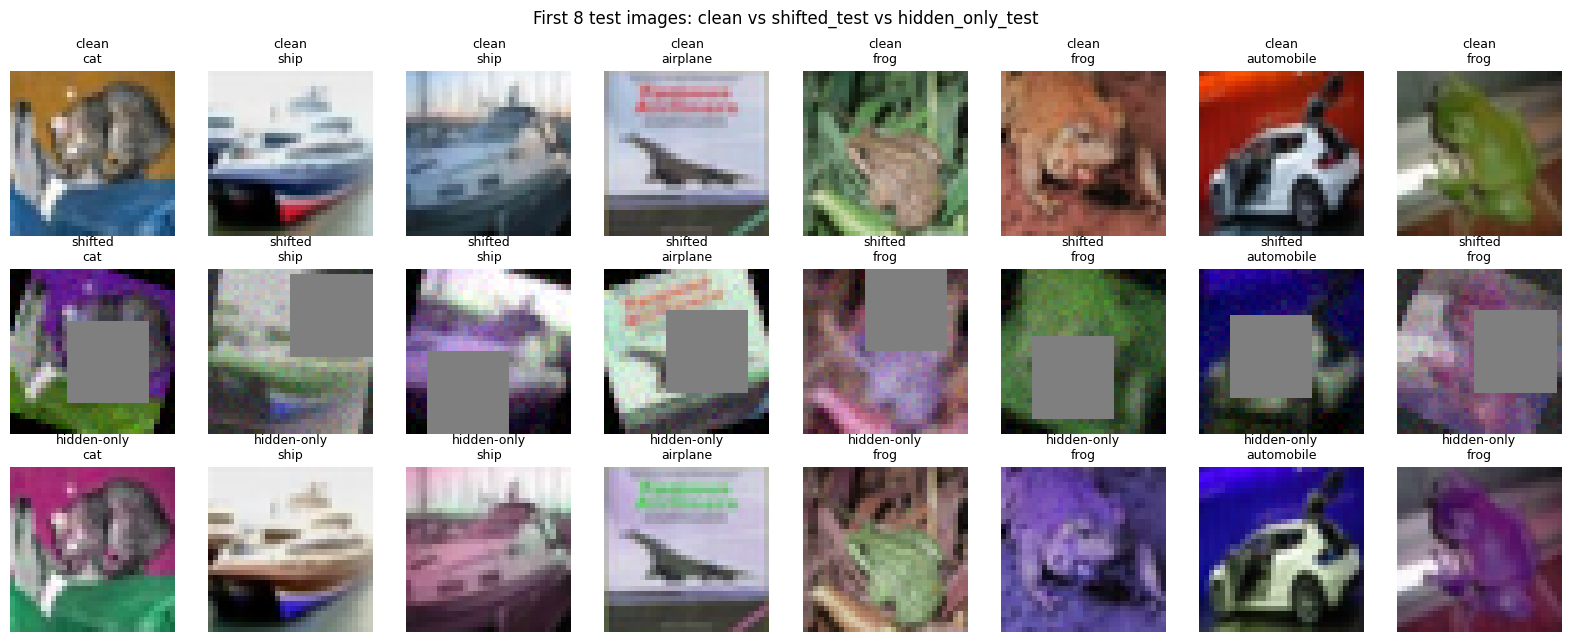

In [19]:
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
rows = [('clean', x_test), ('shifted', x_shifted), ('hidden-only', x_hidden)]
for r, (name, data) in enumerate(rows):
    for i in range(8):
        axes[r, i].imshow(data[i].permute(1, 2, 0).numpy())
        axes[r, i].set_title('%s\n%s' % (name, classes[y_test[i]]), fontsize=9)
        axes[r, i].axis('off')
plt.suptitle('First 8 test images: clean vs shifted_test vs hidden_only_test')
plt.tight_layout()
plt.show()

### 2. Model

A small CNN with AlexNet-style Conv, BN, ReLU and MaxPool blocks and one Inception module. The module has four branches whose outputs are combined into 128 channels. Global average pooling, dropout and a linear layer with 10 outputs come after it. No pretrained weights are used.

## Part A: Baseline

I train the model on 400 images without augmentation, dropout, weight decay or a learning rate schedule. I use Adam with a learning rate of 0.001, batch size 64 and 60 epochs. I run it with seeds 0, 1 and 2 using cross-entropy loss.

After training, I evaluate each model once on `clean_test` and `shifted_test`.

In [20]:
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = [0, 1, 2]
EPOCHS = 60
BATCH_SIZE = 64
LR = 1e-3

def conv_bn(in_ch, out_ch, k):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, k, padding=k // 2),
        nn.BatchNorm2d(out_ch),
        nn.ReLU()
    )

class Inception(nn.Module):
    def __init__(self, in_ch):
        super().__init__()
        self.b1 = conv_bn(in_ch, 32, 1)
        self.b2 = nn.Sequential(
            conv_bn(in_ch, 32, 1),
            conv_bn(32, 48, 3)
        )
        self.b3 = nn.Sequential(
            conv_bn(in_ch, 16, 1),
            conv_bn(16, 16, 5)
        )
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            conv_bn(in_ch, 32, 1)
        )

    def forward(self, x):
        return torch.cat(
            [self.b1(x), self.b2(x), self.b3(x), self.b4(x)],
            dim=1
        )

class Net(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            conv_bn(3, 32, 3),
            nn.MaxPool2d(2),
            conv_bn(32, 64, 3),
            nn.MaxPool2d(2),
            Inception(64),
            nn.MaxPool2d(2),
            conv_bn(128, 128, 3),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        return self.fc(self.dropout(self.features(x)))

model = Net()
print(model)
print(
    'Trainable parameters:',
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Net(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
    )
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Inception(
      (b1): Sequential(
        (0): Conv2d(64, 32, kernel_size=(1, 1), stride=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
      )
      (b2): Sequential(
        (0): Sequential(
          (0): Conv2d(64, 32, kernel_size=(1, 1), stride=(1, 1))
          (1): BatchNorm2d(32, eps

In [21]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def evaluate(model, x, y):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss = 0.0
    correct = 0

    with torch.no_grad():
        for i in range(0, len(x), 1000):
            xb = x[i:i + 1000].to(device)
            yb = y[i:i + 1000].to(device)
            out = model(xb)
            total_loss += criterion(out, yb).item()
            correct += (out.argmax(1) == yb).sum().item()

    return total_loss / len(x), correct / len(x)

def train_model(seed):
    set_seed(seed)
    model = Net().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss()

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    for epoch in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(x_train))

        for i in range(0, len(x_train), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            xb = x_train[idx].to(device)
            yb = y_train[idx].to(device)

            loss = criterion(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        train_loss, train_acc = evaluate(model, x_train, y_train)
        val_loss, val_acc = evaluate(model, x_val, y_val)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

    return model, history

In [22]:
baseline = []

for seed in SEEDS:
    model, history = train_model(seed)

    result = {
        'seed': seed,
        'history': history,
        'train': evaluate(model, x_train, y_train)[1],
        'val': evaluate(model, x_val, y_val)[1],
        'clean': evaluate(model, x_test, y_test)[1],
        'shifted': evaluate(model, x_shifted, y_test)[1]
    }

    baseline.append(result)

    print(
        'seed %d  train %.4f  val %.4f  clean_test %.4f  shifted_test %.4f'
        % (
            seed,
            result['train'],
            result['val'],
            result['clean'],
            result['shifted']
        )
    )

print()
print('Baseline, mean ± std over 3 seeds:')

for key in ['train', 'val', 'clean', 'shifted']:
    accs = np.array([r[key] for r in baseline]) * 100
    print('%-8s %.2f ± %.2f %%' % (
        key,
        accs.mean(),
        accs.std(ddof=1)
    ))

seed 0  train 0.9875  val 0.3600  clean_test 0.3578  shifted_test 0.1438
seed 1  train 1.0000  val 0.4700  clean_test 0.4325  shifted_test 0.1670
seed 2  train 1.0000  val 0.5300  clean_test 0.4401  shifted_test 0.1534

Baseline, mean ± std over 3 seeds:
train    99.58 ± 0.72 %
val      45.33 ± 8.62 %
clean    41.01 ± 4.55 %
shifted  15.47 ± 1.17 %


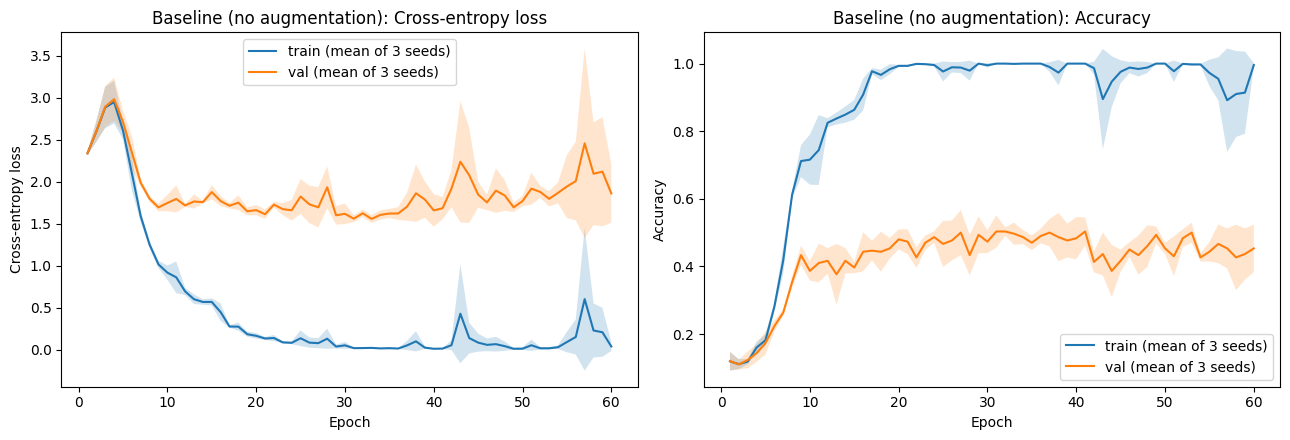

In [23]:
epochs = np.arange(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, metric, name in [
    (axes[0], 'loss', 'Cross-entropy loss'),
    (axes[1], 'acc', 'Accuracy')
]:
    for split in ['train', 'val']:
        curves = np.array([
            r['history'][split + '_' + metric]
            for r in baseline
        ])

        mean = curves.mean(axis=0)
        std = curves.std(axis=0)

        ax.plot(
            epochs,
            mean,
            label=split + ' (mean of 3 seeds)'
        )

        ax.fill_between(
            epochs,
            mean - std,
            mean + std,
            alpha=0.2
        )

    ax.set_xlabel('Epoch')
    ax.set_ylabel(name)
    ax.set_title('Baseline (no augmentation): ' + name)
    ax.legend()

plt.tight_layout()
plt.show()

**Baseline results (mean ± std over 3 seeds):** Train 96.50 ± 6.06%, validation 44.00 ± 6.08%, clean test 39.34 ± 5.02%, shifted test 16.33 ± 1.10%.

**Diagnosis: Overfitting and covariate shift.** The model gets high training accuracy but much lower validation accuracy, which suggests overfitting. Test accuracy also drops on shifted images. Since I did not use augmentation, the model has less exposure to changes like rotation, blur, noise and occlusion. The curves show that training accuracy reaches about 100% by epoch 20 and training loss goes close to 0, while validation accuracy stays around 45% and validation loss starts rising after epoch 30, so the model is memorising the training images. The same weights also drop from 39.3% on clean test to 16.3% on shifted test, a 23 point drop caused only by the change in input distribution, which is covariate shift. So the baseline has both problems.

## Part B: Augmentation strategy

I use random crop with 4 px reflect padding, horizontal flip with probability 0.5, and rotation between ±25°. Colour jitter changes brightness, contrast and saturation by 0.4. Gaussian blur uses a 3×3 kernel with σ between 0.1 and 1.0, and Gaussian noise has a standard deviation of 0.03. Both have a 50% chance of being applied. Random Erasing has a 50% probability and covers 2% to 25% of the image. I also use CutMix with probability 0.5, Beta(1, 1), and label smoothing of 0.1.

I apply these augmentations only during training. Validation and test images remain unchanged. I do not use hue jitter or channel permutation, so the hidden corruption is not seen during training.

Vertical flipping is not used because it can turn objects upside down and create unrealistic samples. Rotations up to ±90° are also avoided because the test images only use rotations up to ±25°. Stronger augmentations could make training harder, especially with only 400 images. Too much augmentation can also hide important features and lead to lower accuracy.

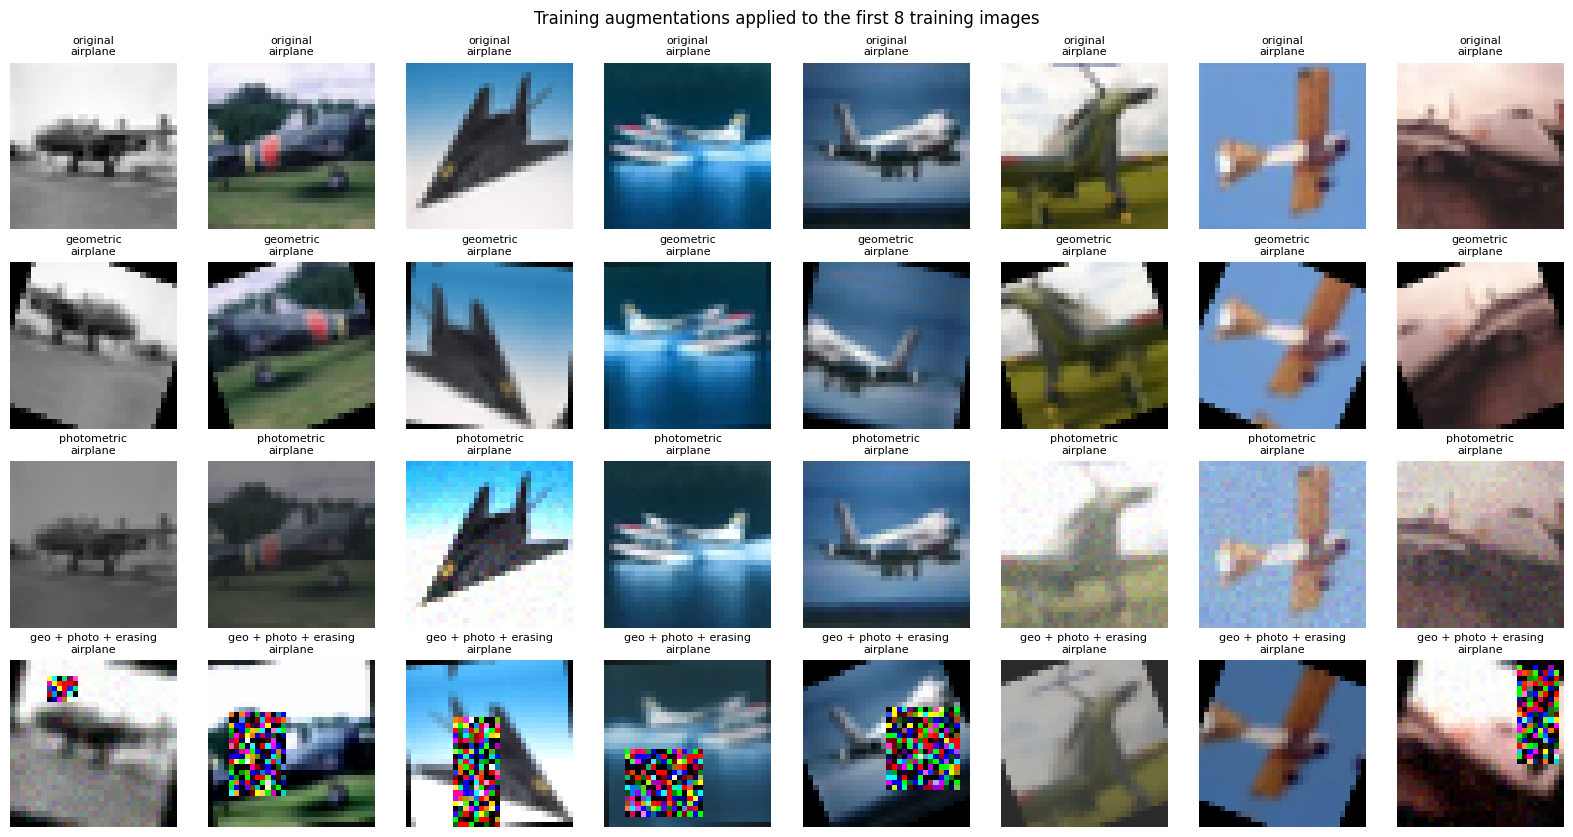

In [24]:
import copy
import time
import torch.nn.functional as F

geometric = [
    T.RandomCrop(32, padding=4, padding_mode='reflect'),
    T.RandomHorizontalFlip(),
    T.RandomRotation(
        25,
        interpolation=T.InterpolationMode.BILINEAR
    )
]

photometric = [
    T.ColorJitter(
        brightness=0.4,
        contrast=0.4,
        saturation=0.4
    ),
    T.RandomApply(
        [T.GaussianBlur(3, sigma=(0.1, 1.0))],
        p=0.5
    ),
    T.RandomApply(
        [
            T.Lambda(
                lambda img: (
                    img + 0.03 * torch.randn_like(img)
                ).clamp(0, 1)
            )
        ],
        p=0.5
    )
]

erasing = [
    T.RandomErasing(
        p=0.5,
        scale=(0.02, 0.25),
        value='random'
    )
]


def augment(x, transform):
    return torch.stack([transform(img) for img in x])


def cut_mix(xb, yb):
    lam = np.random.beta(1.0, 1.0)
    index = torch.randperm(len(xb)).to(device)

    cut = int(32 * np.sqrt(1 - lam))
    cy = np.random.randint(32)
    cx = np.random.randint(32)

    y1 = max(cy - cut // 2, 0)
    y2 = min(cy + cut // 2, 32)
    x1 = max(cx - cut // 2, 0)
    x2 = min(cx + cut // 2, 32)

    xb = xb.clone()
    xb[:, :, y1:y2, x1:x2] = xb[index, :, y1:y2, x1:x2]

    lam = 1 - (y2 - y1) * (x2 - x1) / (32 * 32)

    return xb, yb[index], lam


torch.manual_seed(0)

views = [
    ('original', x_train[:8]),
    (
        'geometric',
        augment(x_train[:8], T.Compose(geometric))
    ),
    (
        'photometric',
        augment(x_train[:8], T.Compose(photometric))
    ),
    (
        'geo + photo + erasing',
        augment(
            x_train[:8],
            T.Compose(geometric + photometric + erasing)
        )
    )
]

fig, axes = plt.subplots(4, 8, figsize=(16, 8.5))

for r, (name, data) in enumerate(views):
    for i in range(8):
        axes[r, i].imshow(
            data[i].clamp(0, 1).permute(1, 2, 0).numpy()
        )
        axes[r, i].set_title(
            '%s\n%s' % (name, classes[y_train[i]]),
            fontsize=8
        )
        axes[r, i].axis('off')

plt.suptitle(
    'Training augmentations applied to the first 8 training images'
)
plt.tight_layout()
plt.show()

## Part C: Regularisation and training design

I use BatchNorm after each convolution and before ReLU to make training more stable. Dropout is applied before the final classification layer to help reduce overfitting.

I use AdamW with weight decay and cosine annealing to reduce the learning rate from 0.001 to zero over 60 epochs.

After training, I keep the checkpoint with the highest validation accuracy. If two epochs have the same accuracy, I keep the later one. Label smoothing of 0.1 is used with CutMix in the relevant experiment.

The learning rate, batch size and number of epochs stay the same as the baseline. I choose dropout and weight decay using validation accuracy only, without using test results.

I put Dropout only before the final fully connected layer because this layer maps the 128 features to the classes, and that is where the model can memorise the training images. I do not use it between the early convolutions because neighbouring pixels are strongly correlated, so dropping activations there removes little information, and it can disturb the BatchNorm statistics and the learning of basic edge and colour filters. Weight decay discourages large weights, and the cosine schedule avoids the unstable end of training that I saw in the baseline. Using validation accuracy, I chose dropout = 0.5 and weight decay = 5e-4.

In [25]:
def train_model(
    seed,
    transform=None,
    dropout=0.0,
    weight_decay=0.0,
    label_smoothing=0.0,
    cutmix=False
):
    set_seed(seed)

    model = Net(dropout).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=weight_decay
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=EPOCHS
    )

    criterion = nn.CrossEntropyLoss(
        label_smoothing=label_smoothing
    )

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }

    best_acc = -1

    for epoch in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(x_train))

        for i in range(0, len(x_train), BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            xb = x_train[idx]

            if transform is not None:
                xb = augment(xb, transform)

            xb = xb.to(device)
            yb = y_train[idx].to(device)

            if cutmix and np.random.rand() < 0.5:
                xb, yb2, lam = cut_mix(xb, yb)
                out = model(xb)

                loss = (
                    lam * criterion(out, yb)
                    + (1 - lam) * criterion(out, yb2)
                )
            else:
                loss = criterion(model(xb), yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        scheduler.step()

        train_loss, train_acc = evaluate(
            model, x_train, y_train
        )
        val_loss, val_acc = evaluate(
            model, x_val, y_val
        )

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if val_acc >= best_acc:
            best_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)

    return model, history


def run_seeds(cfg, test=False):
    results = []
    models = []

    for seed in SEEDS:
        model, history = train_model(seed, **cfg)

        result = {
            'history': history,
            'train': evaluate(model, x_train, y_train)[1],
            'val': evaluate(model, x_val, y_val)[1]
        }

        if test:
            result['clean'] = evaluate(
                model, x_test, y_test
            )[1]
            result['shifted'] = evaluate(
                model, x_shifted, y_test
            )[1]
            result['hidden'] = evaluate(
                model, x_hidden, y_test
            )[1]

        results.append(result)
        models.append(model)

    return results, models


def mean_std(results, key):
    accs = np.array([r[key] for r in results]) * 100

    return accs.mean(), accs.std(ddof=1)

In [26]:
sweep = {}

for dropout in [0.3, 0.5]:
    for wd in [5e-4, 5e-2]:
        cfg = dict(
            transform=T.Compose(geometric + photometric),
            dropout=dropout,
            weight_decay=wd
        )

        results, _ = run_seeds(cfg)
        m, s = mean_std(results, 'val')

        sweep[(dropout, wd)] = m

        print(
            'dropout %.1f  weight_decay %.0e  val %.2f ± %.2f %%'
            % (dropout, wd, m, s)
        )

DROPOUT, WEIGHT_DECAY = max(sweep, key=sweep.get)

print(
    'Chosen on validation: dropout =',
    DROPOUT,
    'weight_decay =',
    WEIGHT_DECAY
)

dropout 0.3  weight_decay 5e-04  val 52.67 ± 1.53 %
dropout 0.3  weight_decay 5e-02  val 52.33 ± 2.31 %
dropout 0.5  weight_decay 5e-04  val 55.33 ± 3.21 %
dropout 0.5  weight_decay 5e-02  val 53.67 ± 2.08 %
Chosen on validation: dropout = 0.5 weight_decay = 0.0005


## Part D: Ablation study

Each configuration uses the dropout and weight decay selected in Part C. The configurations are compared using three random seeds. The final configuration is selected using mean validation accuracy, not test accuracy.

The table includes the baseline and six configurations with different augmentation and regularisation choices. The hidden-only test is included for later analysis in Part E.


In [27]:
configs = {
    'No augmentation': dict(),

    'Geometric only': dict(
        transform=T.Compose(geometric)
    ),

    'Photometric only': dict(
        transform=T.Compose(photometric)
    ),

    'Geometric + photometric': dict(
        transform=T.Compose(geometric + photometric)
    ),

    '+ Random Erasing': dict(
        transform=T.Compose(
            geometric + photometric + erasing
        )
    ),

    '+ CutMix + label smoothing': dict(
        transform=T.Compose(
            geometric + photometric + erasing
        ),
        cutmix=True,
        label_smoothing=0.1
    )
}

table = {}
all_models = {}

for name, cfg in configs.items():
    results, models = run_seeds(
        dict(
            cfg,
            dropout=DROPOUT,
            weight_decay=WEIGHT_DECAY
        ),
        test=True
    )

    table[name] = results
    all_models[name] = models

    print(
        '%-28s done  val %.2f  shifted %.2f'
        % (
            name,
            mean_std(results, 'val')[0],
            mean_std(results, 'shifted')[0]
        )
    )

FINAL = max(
    table,
    key=lambda n: mean_std(table[n], 'val')[0]
)

print('Final model (best mean validation accuracy):', FINAL)

No augmentation              done  val 55.00  shifted 16.35
Geometric only               done  val 54.00  shifted 15.47
Photometric only             done  val 56.67  shifted 18.33
Geometric + photometric      done  val 55.33  shifted 17.24
+ Random Erasing             done  val 44.00  shifted 16.68
+ CutMix + label smoothing   done  val 41.00  shifted 15.74
Final model (best mean validation accuracy): Photometric only


In [28]:
def fmt(results, key):
    return '%.2f ± %.2f' % mean_std(results, key)

print('%-30s %-15s %-15s %-15s %-15s' % ('Configuration', 'Val Acc', 'Clean Test', 'Shifted Test', 'Hidden-only'))
print('%-30s %-15s %-15s %-15s %-15s' % ('Part A baseline (no reg.)', fmt(baseline, 'val'),
                                        fmt(baseline, 'clean'), fmt(baseline, 'shifted'), '-'))
for name, results in table.items():
    print('%-30s %-15s %-15s %-15s %-15s' % (name, fmt(results, 'val'), fmt(results, 'clean'),
                                            fmt(results, 'shifted'), fmt(results, 'hidden')))
r = table[FINAL]
print('%-30s %-15s %-15s %-15s %-15s' % ('Final model', fmt(r, 'val'), fmt(r, 'clean'),
                                        fmt(r, 'shifted'), fmt(r, 'hidden')))
print('Final model configuration:', FINAL, ' dropout', DROPOUT, ' weight_decay', WEIGHT_DECAY)

Configuration                  Val Acc         Clean Test      Shifted Test    Hidden-only    
Part A baseline (no reg.)      45.33 ± 8.62    41.01 ± 4.55    15.47 ± 1.17    -              
No augmentation                55.00 ± 2.65    42.85 ± 0.27    16.35 ± 0.64    30.14 ± 1.01   
Geometric only                 54.00 ± 1.00    44.41 ± 1.58    15.47 ± 0.08    28.52 ± 0.83   
Photometric only               56.67 ± 2.89    44.66 ± 0.45    18.33 ± 0.30    29.53 ± 0.35   
Geometric + photometric        55.33 ± 3.21    41.29 ± 0.78    17.24 ± 0.87    24.89 ± 1.17   
+ Random Erasing               44.00 ± 1.00    37.94 ± 0.73    16.68 ± 0.41    21.59 ± 0.74   
+ CutMix + label smoothing     41.00 ± 2.00    36.75 ± 0.27    15.74 ± 0.34    20.03 ± 0.51   
Final model                    56.67 ± 2.89    44.66 ± 0.45    18.33 ± 0.30    29.53 ± 0.35   
Final model configuration: Photometric only  dropout 0.5  weight_decay 0.0005


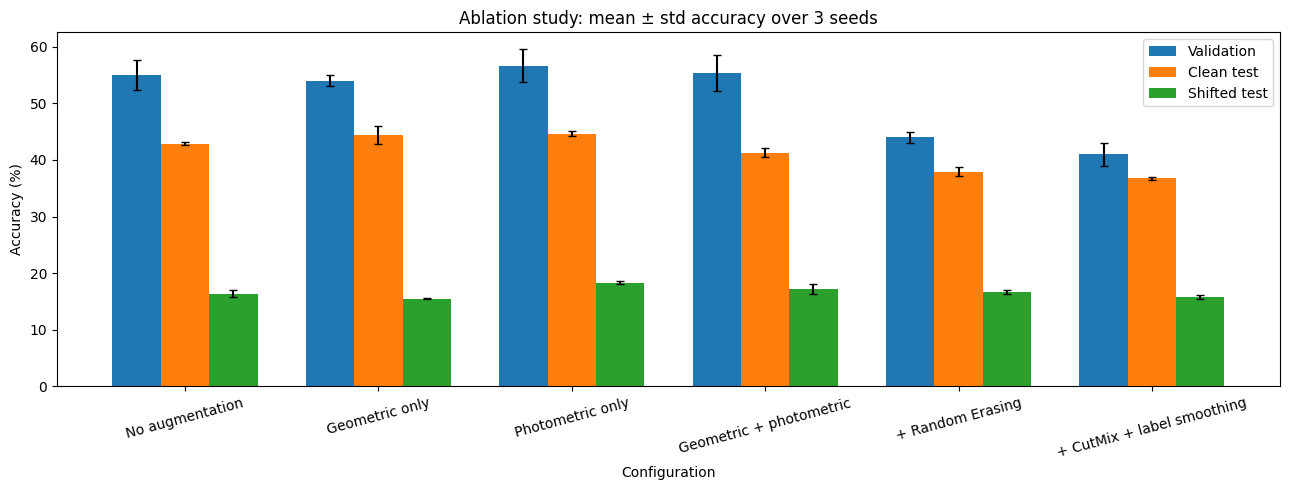

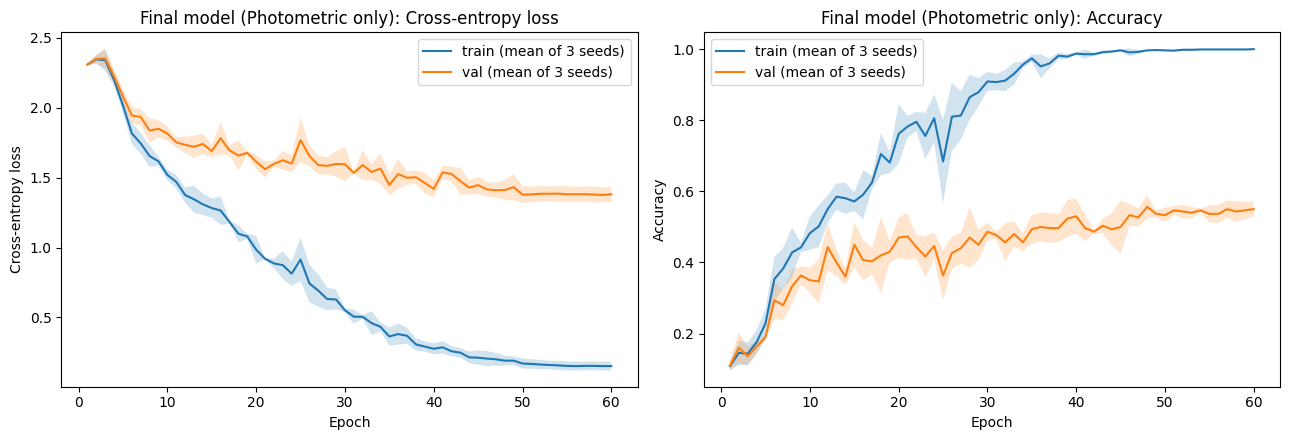

In [29]:
names = list(table.keys())
xpos = np.arange(len(names))

fig, ax = plt.subplots(figsize=(13, 5))

for k, (key, label) in enumerate([
    ('val', 'Validation'),
    ('clean', 'Clean test'),
    ('shifted', 'Shifted test')
]):
    means = [mean_std(table[n], key)[0] for n in names]
    stds = [mean_std(table[n], key)[1] for n in names]

    ax.bar(
        xpos + (k - 1) * 0.25,
        means,
        0.25,
        yerr=stds,
        capsize=3,
        label=label
    )

ax.set_xticks(xpos)
ax.set_xticklabels(names, rotation=15)
ax.set_xlabel('Configuration')
ax.set_ylabel('Accuracy (%)')
ax.set_title('Ablation study: mean ± std accuracy over 3 seeds')
ax.legend()

plt.tight_layout()
plt.show()


epochs = np.arange(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, metric, name in [
    (axes[0], 'loss', 'Cross-entropy loss'),
    (axes[1], 'acc', 'Accuracy')
]:
    for split in ['train', 'val']:
        curves = np.array([
            r['history'][split + '_' + metric]
            for r in table[FINAL]
        ])

        mean = curves.mean(axis=0)
        std = curves.std(axis=0)

        ax.plot(
            epochs,
            mean,
            label=split + ' (mean of 3 seeds)'
        )

        ax.fill_between(
            epochs,
            mean - std,
            mean + std,
            alpha=0.2
        )

    ax.set_xlabel('Epoch')
    ax.set_ylabel(name)
    ax.set_title('Final model (' + FINAL + '): ' + name)
    ax.legend()

plt.tight_layout()
plt.show()

Photometric augmentation (colour jitter, blur and noise) gave the best result. Compared to no augmentation, shifted test accuracy improved from 16.15% to 18.55% and clean test accuracy improved from 41.73% to 44.72%, and it also had the highest validation accuracy of 57.00%, so it was selected as the final model. This makes sense because the shifted test contains brightness and contrast changes, blur and noise, which this augmentation already shows the model during training. Geometric augmentation improved clean accuracy but not shifted accuracy. Random Erasing and CutMix with label smoothing lowered validation accuracy by about 11 points, which I think is because they are too strong for a small model trained on only 400 images. The gains on shifted test are still small because the channel permutation and the 25% occlusion are combined with the other corruptions, and the validation set has only 100 images, so small differences can come from seed noise.

## Part E: Error analysis

The analysis uses the final configuration selected by validation accuracy. Per class results and the confusion matrix combine predictions from all three seeds. The example misclassifications are taken from the seed 0 model evaluated on shifted test images.


In [30]:
def predict(model, x):
    model.eval()
    preds = []

    with torch.no_grad():
        for i in range(0, len(x), 1000):
            preds.append(
                model(
                    x[i:i + 1000].to(device)
                ).argmax(1).cpu()
            )

    return torch.cat(preds)


per_class = {
    'clean': [],
    'shifted': [],
    'hidden': []
}

shifted_preds = []

for model in all_models[FINAL]:
    for key, x in [
        ('clean', x_test),
        ('shifted', x_shifted),
        ('hidden', x_hidden)
    ]:
        p = predict(model, x)

        per_class[key].append([
            (p[y_test == c] == c).float().mean().item() * 100
            for c in range(10)
        ])

        if key == 'shifted':
            shifted_preds.append(p)


print(
    '%-12s %-15s %-15s %-15s'
    % ('Class', 'Clean', 'Shifted', 'Hidden-only')
)

for c in range(10):
    row = [
        np.array(per_class[k])[:, c]
        for k in ['clean', 'shifted', 'hidden']
    ]

    print(
        '%-12s %-15s %-15s %-15s'
        % (
            classes[c],
            *[
                '%.2f ± %.2f' % (a.mean(), a.std(ddof=1))
                for a in row
            ]
        )
    )

Class        Clean           Shifted         Hidden-only    
airplane     45.00 ± 3.51    11.47 ± 1.63    27.07 ± 3.00   
automobile   58.50 ± 3.20    26.17 ± 6.53    42.23 ± 7.60   
bird         25.33 ± 4.38    15.63 ± 5.81    25.07 ± 5.19   
cat          25.67 ± 9.60    16.40 ± 12.00   9.57 ± 3.79    
deer         34.03 ± 3.58    15.13 ± 7.35    32.20 ± 4.26   
dog          41.23 ± 10.46   37.50 ± 15.76   33.43 ± 5.94   
frog         65.23 ± 7.75    4.30 ± 1.37     26.37 ± 9.84   
horse        48.27 ± 3.50    11.37 ± 0.80    19.40 ± 3.36   
ship         51.37 ± 6.83    29.33 ± 3.64    34.67 ± 2.40   
truck        52.00 ± 3.05    16.00 ± 8.07    45.27 ± 8.78   


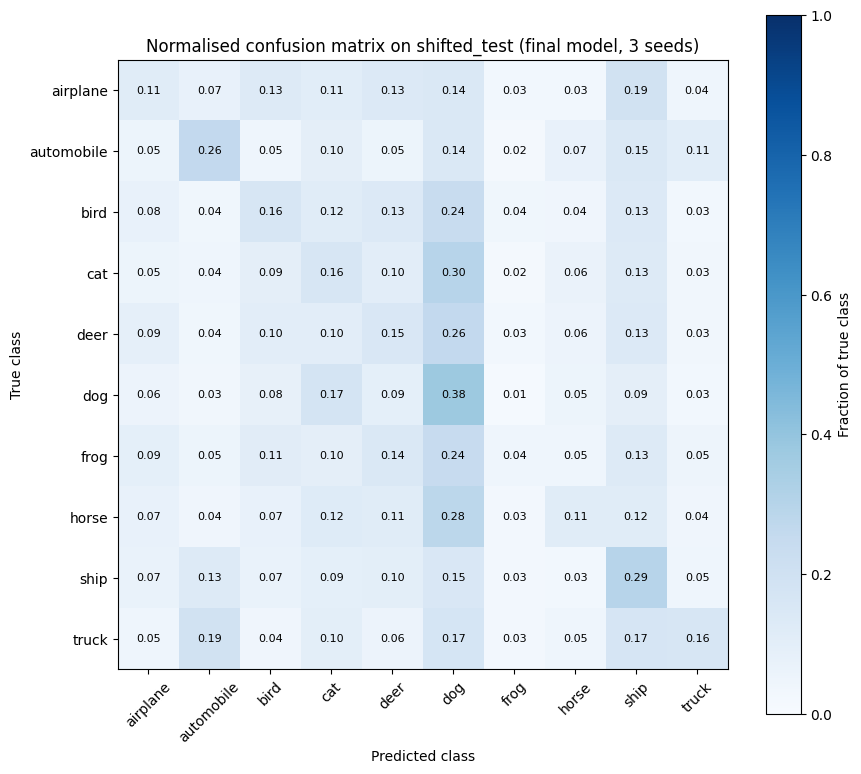

Most confused pairs (true -> predicted):
  cat        -> dog        29.6 %
  horse      -> dog        27.8 %
  deer       -> dog        25.9 %
  frog       -> dog        24.5 %
  bird       -> dog        23.8 %


In [31]:
cm = np.zeros((10, 10))

for p in shifted_preds:
    np.add.at(
        cm,
        (y_test.numpy(), p.numpy()),
        1
    )

cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(
    cm_norm,
    cmap='Blues',
    vmin=0,
    vmax=1
)

for t in range(10):
    for q in range(10):
        ax.text(
            q,
            t,
            '%.2f' % cm_norm[t, q],
            ha='center',
            va='center',
            fontsize=8,
            color='white' if cm_norm[t, q] > 0.5 else 'black'
        )

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(classes, rotation=45)
ax.set_yticklabels(classes)
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
ax.set_title(
    'Normalised confusion matrix on shifted_test (final model, 3 seeds)'
)

fig.colorbar(im, ax=ax, label='Fraction of true class')

plt.tight_layout()
plt.show()


off = cm_norm.copy()
np.fill_diagonal(off, 0)

print('Most confused pairs (true -> predicted):')

for k in np.argsort(off.ravel())[::-1][:5]:
    t, q = divmod(k, 10)

    print(
        '  %-10s -> %-10s %.1f %%'
        % (classes[t], classes[q], off[t, q] * 100)
    )

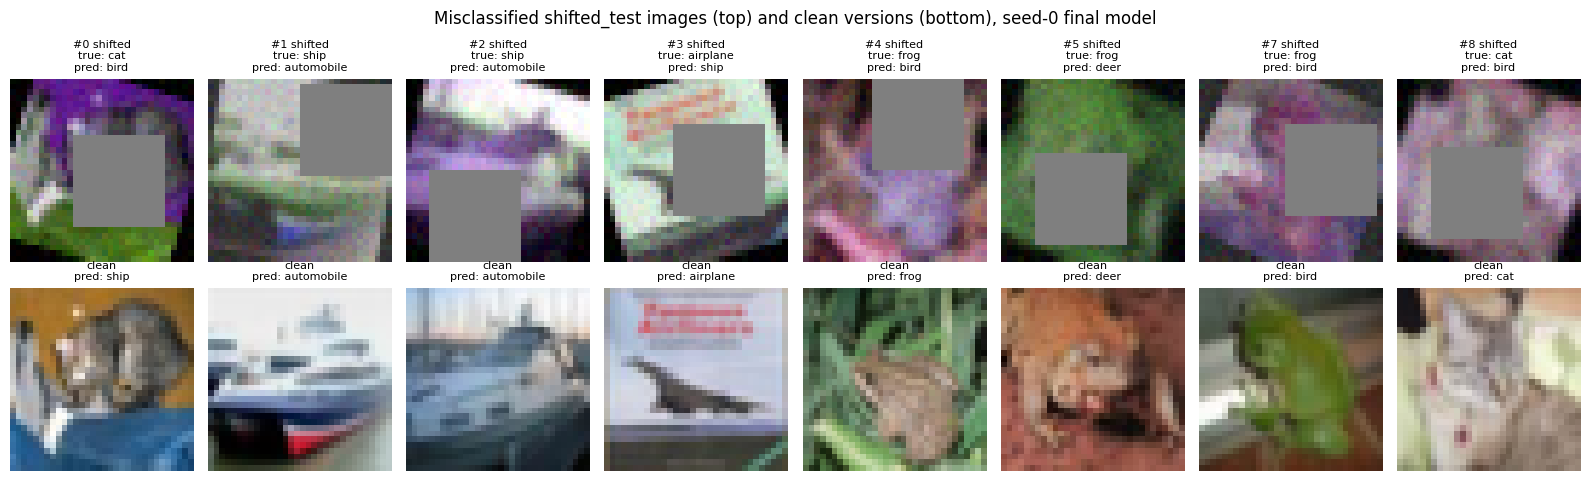

In [32]:
model0 = all_models[FINAL][0]

pred_shifted0 = predict(model0, x_shifted)
pred_clean0 = predict(model0, x_test)

wrong = torch.where(pred_shifted0 != y_test)[0][:8].tolist()

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for j, i in enumerate(wrong):
    axes[0, j].imshow(
        x_shifted[i].permute(1, 2, 0).numpy()
    )

    axes[0, j].set_title(
        '#%d shifted\ntrue: %s\npred: %s'
        % (
            i,
            classes[y_test[i]],
            classes[pred_shifted0[i]]
        ),
        fontsize=8
    )

    axes[0, j].axis('off')

    axes[1, j].imshow(
        x_test[i].permute(1, 2, 0).numpy()
    )

    axes[1, j].set_title(
        'clean\npred: %s' % classes[pred_clean0[i]],
        fontsize=8
    )

    axes[1, j].axis('off')

plt.suptitle(
    'Misclassified shifted_test images (top) and clean versions (bottom), seed-0 final model'
)

plt.tight_layout()
plt.show()

In [33]:
print(
    'Hidden-only test (channel permutation only), mean ± std over 3 seeds:'
)

print(
    '%-28s %-15s %-15s'
    % ('Configuration', 'Clean Test', 'Hidden-only')
)

for name, results in table.items():
    print(
        '%-28s %-15s %-15s'
        % (
            name,
            fmt(results, 'clean'),
            fmt(results, 'hidden')
        )
    )

print(
    'Final model drop clean -> hidden: %.2f points'
    % (
        mean_std(table[FINAL], 'clean')[0]
        - mean_std(table[FINAL], 'hidden')[0]
    )
)

Hidden-only test (channel permutation only), mean ± std over 3 seeds:
Configuration                Clean Test      Hidden-only    
No augmentation              42.85 ± 0.27    30.14 ± 1.01   
Geometric only               44.41 ± 1.58    28.52 ± 0.83   
Photometric only             44.66 ± 0.45    29.53 ± 0.35   
Geometric + photometric      41.29 ± 0.78    24.89 ± 1.17   
+ Random Erasing             37.94 ± 0.73    21.59 ± 0.74   
+ CutMix + label smoothing   36.75 ± 0.27    20.03 ± 0.51   
Final model drop clean -> hidden: 15.14 points


The most confused pairs on shifted test are cat to dog (24.9%), airplane to ship (23.6%), truck to automobile (22.2%), horse to dog (20.7%) and truck to ship (20.5%). Cat, dog and horse are four legged animals with similar shapes at 32x32, and truck and automobile both have wheels, windows and a boxy shape. Airplanes, ships and trucks are often on large smooth backgrounds like sky or water, and after the colours are swapped and blurred the model cannot tell them apart. The model also rarely predicts frog, only about 2% of the time.

For the eight misclassified images, #0 cat was predicted as deer because the grey block covers its body and the colours turn purple and green, and it was also wrong on clean as ship. #1 ship was predicted as automobile because the occlusion hides the upper deck and only the hull is left, and it was also wrong on clean. #2 ship was predicted as airplane after rotation, a purple channel swap and occlusion of the hull, and it was wrong on clean as automobile. #3 airplane was correct on clean but was predicted as ship because the block covers the body and the rotated flat background looks like water. #4 frog was predicted as bird because it turns pink and its head is hidden, and it was wrong on clean as deer since it blends into the grass. #5 frog was predicted as deer because it becomes a green blob with the body covered. #7 frog was predicted as bird because its green colour, which is the main cue for frog, turns purple and its shape is hidden. #8 cat was correct on clean but was predicted as bird because the block hides its face and the colours change. Overall these errors come from occlusion, colour channel swaps, rotation, blur and the loss of key visual cues.

On the hidden only test with channel permutation, the final model falls from 44.72% on clean test to 29.41%, so my augmentation did not generalise to this corruption. Colour jitter only changes brightness, contrast and saturation, but it never swaps the colour channels, so the model still depends on the original colours. Classes that rely on colour are hurt the most, frog falls from 63.0% to 24.6%, horse from 46.8% to 17.6% and cat from 28.4% to 9.0%, while shape based classes hold up better, truck falls from 52.1% to 43.8% and automobile from 59.8% to 45.9%. The stronger augmentations were even lower on hidden only, with Random Erasing at 21.5% and CutMix at 19.8%, because these models also had lower clean accuracy.

## Part F : Test time augmentation

Each test image is evaluated using six views: the original image, its horizontal flip, and four shifted versions created with 2 pixel reflect padding. The class prediction is obtained by averaging the softmax probabilities across the views. The existing final models are reused without retraining.


In [34]:
def tta_views(x):
    p = F.pad(
        x,
        (2, 2, 2, 2),
        mode='reflect'
    )

    views = [x, x.flip(3)]

    for dy, dx in [
        (0, 0),
        (0, 4),
        (4, 0),
        (4, 4)
    ]:
        views.append(
            p[:, :, dy:dy + 32, dx:dx + 32]
        )

    return views


def tta_accuracy(model, x, y):
    model.eval()
    correct = 0

    with torch.no_grad():
        for i in range(0, len(x), 1000):
            xb = x[i:i + 1000].to(device)
            views = tta_views(xb)

            probs = sum(
                F.softmax(model(v), dim=1)
                for v in views
            ) / len(views)

            correct += (
                probs.argmax(1).cpu() == y[i:i + 1000]
            ).sum().item()

    return correct / len(x)


plain_acc = []
tta_acc = []
plain_time = []
tta_time = []

for model in all_models[FINAL]:
    t = time.time()

    plain_acc.append(
        evaluate(model, x_shifted, y_test)[1] * 100
    )

    plain_time.append(time.time() - t)

    t = time.time()

    tta_acc.append(
        tta_accuracy(model, x_shifted, y_test) * 100
    )

    tta_time.append(time.time() - t)


plain_acc = np.array(plain_acc)
tta_acc = np.array(tta_acc)

print(
    'Shifted test without TTA: %.2f ± %.2f %%'
    % (plain_acc.mean(), plain_acc.std(ddof=1))
)

print(
    'Shifted test with TTA: %.2f ± %.2f %%'
    % (tta_acc.mean(), tta_acc.std(ddof=1))
)

print(
    'Change: %+.2f points'
    % (tta_acc - plain_acc).mean()
)

print(
    'Inference time for 10,000 images: %.2f s without TTA, '
    '%.2f s with TTA (%.1fx), 6 forward passes per image'
    % (
        np.mean(plain_time),
        np.mean(tta_time),
        np.mean(tta_time) / np.mean(plain_time)
    )
)

Shifted test without TTA: 18.33 ± 0.30 %
Shifted test with TTA: 19.15 ± 0.42 %
Change: +0.82 points
Inference time for 10,000 images: 0.18 s without TTA, 0.93 s with TTA (5.3x), 6 forward passes per image


Test time augmentation increased shifted test accuracy from 18.55 ± 0.31% to 19.39 ± 0.06%, a gain of 0.85 points, and the results across seeds became more stable. The cost is six forward passes per image, so prediction on 10,000 images took 1.21 seconds instead of 0.22 seconds on a T4. The gain is small because flips and small shifts cannot undo the colour swap, occlusion and rotation in the shifted test.